In [1]:
import io
import os
import pandas as pd
import paramiko
import matplotlib.pyplot as plt
# --- 提供いただいたヘッダー見本（タブ区切りテキスト） ---
raw_header_text = """Timestamp (end of interval)	Int Temp (ｰC)	Ext Temp (ｰC)	Pressure (hPa)	Rel Humidity (%)	Wiper count	Vbatt (V)	40m Wind Speed (m/s)	40m Wind Speed Dispersion (m/s)	40m Wind Speed min (m/s)	40m Wind Speed max (m/s)	40m Wind Direction (ｰ)	40m Z-wind (m/s)	40m Z-wind Dispersion (m/s)	40m CNR (dB)	40m CNR min (dB)	40m Dopp Spect Broad (m/s)	40m Data Availability (%)		60m Wind Speed (m/s)	60m Wind Speed Dispersion (m/s)	60m Wind Speed min (m/s)	60m Wind Speed max (m/s)	60m Wind Direction (ｰ)	60m Z-wind (m/s)	60m Z-wind Dispersion (m/s)	60m CNR (dB)	60m CNR min (dB)	60m Dopp Spect Broad (m/s)	60m Data Availability (%)		80m Wind Speed (m/s)	80m Wind Speed Dispersion (m/s)	80m Wind Speed min (m/s)	80m Wind Speed max (m/s)	80m Wind Direction (ｰ)	80m Z-wind (m/s)	80m Z-wind Dispersion (m/s)	80m CNR (dB)	80m CNR min (dB)	80m Dopp Spect Broad (m/s)	80m Data Availability (%)		100m Wind Speed (m/s)	100m Wind Speed Dispersion (m/s)	100m Wind Speed min (m/s)	100m Wind Speed max (m/s)	100m Wind Direction (ｰ)	100m Z-wind (m/s)	100m Z-wind Dispersion (m/s)	100m CNR (dB)	100m CNR min (dB)	100m Dopp Spect Broad (m/s)	100m Data Availability (%)		120m Wind Speed (m/s)	120m Wind Speed Dispersion (m/s)	120m Wind Speed min (m/s)	120m Wind Speed max (m/s)	120m Wind Direction (ｰ)	120m Z-wind (m/s)	120m Z-wind Dispersion (m/s)	120m CNR (dB)	120m CNR min (dB)	120m Dopp Spect Broad (m/s)	120m Data Availability (%)		140m Wind Speed (m/s)	140m Wind Speed Dispersion (m/s)	140m Wind Speed min (m/s)	140m Wind Speed max (m/s)	140m Wind Direction (ｰ)	140m Z-wind (m/s)	140m Z-wind Dispersion (m/s)	140m CNR (dB)	140m CNR min (dB)	140m Dopp Spect Broad (m/s)	140m Data Availability (%)		160m Wind Speed (m/s)	160m Wind Speed Dispersion (m/s)	160m Wind Speed min (m/s)	160m Wind Speed max (m/s)	160m Wind Direction (ｰ)	160m Z-wind (m/s)	160m Z-wind Dispersion (m/s)	160m CNR (dB)	160m CNR min (dB)	160m Dopp Spect Broad (m/s)	160m Data Availability (%)		180m Wind Speed (m/s)	180m Wind Speed Dispersion (m/s)	180m Wind Speed min (m/s)	180m Wind Speed max (m/s)	180m Wind Direction (ｰ)	180m Z-wind (m/s)	180m Z-wind Dispersion (m/s)	180m CNR (dB)	180m CNR min (dB)	180m Dopp Spect Broad (m/s)	180m Data Availability (%)		200m Wind Speed (m/s)	200m Wind Speed Dispersion (m/s)	200m Wind Speed min (m/s)	200m Wind Speed max (m/s)	200m Wind Direction (ｰ)	200m Z-wind (m/s)	200m Z-wind Dispersion (m/s)	200m CNR (dB)	200m CNR min (dB)	200m Dopp Spect Broad (m/s)	200m Data Availability (%)		220m Wind Speed (m/s)	220m Wind Speed Dispersion (m/s)	220m Wind Speed min (m/s)	220m Wind Speed max (m/s)	220m Wind Direction (ｰ)	220m Z-wind (m/s)	220m Z-wind Dispersion (m/s)	220m CNR (dB)	220m CNR min (dB)	220m Dopp Spect Broad (m/s)	220m Data Availability (%)		240m Wind Speed (m/s)	240m Wind Speed Dispersion (m/s)	240m Wind Speed min (m/s)	240m Wind Speed max (m/s)	240m Wind Direction (ｰ)	240m Z-wind (m/s)	240m Z-wind Dispersion (m/s)	240m CNR (dB)	240m CNR min (dB)	240m Dopp Spect Broad (m/s)	240m Data Availability (%)		260m Wind Speed (m/s)	260m Wind Speed Dispersion (m/s)	260m Wind Speed min (m/s)	260m Wind Speed max (m/s)	260m Wind Direction (ｰ)	260m Z-wind (m/s)	260m Z-wind Dispersion (m/s)	260m CNR (dB)	260m CNR min (dB)	260m Dopp Spect Broad (m/s)	260m Data Availability (%)		280m Wind Speed (m/s)	280m Wind Speed Dispersion (m/s)	280m Wind Speed min (m/s)	280m Wind Speed max (m/s)	280m Wind Direction (ｰ)	280m Z-wind (m/s)	280m Z-wind Dispersion (m/s)	280m CNR (dB)	280m CNR min (dB)	280m Dopp Spect Broad (m/s)	280m Data Availability (%)		300m Wind Speed (m/s)	300m Wind Speed Dispersion (m/s)	300m Wind Speed min (m/s)	300m Wind Speed max (m/s)	300m Wind Direction (ｰ)	300m Z-wind (m/s)	300m Z-wind Dispersion (m/s)	300m CNR (dB)	300m CNR min (dB)	300m Dopp Spect Broad (m/s)	300m Data Availability (%)"""

clean_headers = [c.strip() for c in raw_header_text.split("\t") if c.strip() != ""]

# --- SFTP接続設定 ---
sftp_host = "172.16.34.223"
sftp_user = "hayashi"
sftp_pass = "hayashi"
remote_dir = "/home/hayashi/kaiseki/SampleData/FREA_LiDAR/WLS71045_sta_files/"

# 1. ここで確実にSSHとSFTPの接続を行います
ssh = paramiko.SSHClient()
ssh.set_missing_host_key_policy(paramiko.AutoAddPolicy())
ssh.connect(sftp_host, username=sftp_user, password=sftp_pass)
sftp = ssh.open_sftp()  # ここで 'sftp' が定義されます

df_list = []

try:
    # 2. 接続が確立された状態でループを回します
    for n in range(1, 29):
        date_str = f"{n:02d}"
        file_name = f"WLS71045_2025_02_{date_str}__00_10_00.sta"
        remote_path = os.path.join(remote_dir, file_name)

        print(f"ファイルを処理中: {file_name}")

        try:
            with sftp.open(remote_path, "rb") as f:
                binary_data = f.read()

            text_data = binary_data.decode("shift_jis", errors="ignore")

            df_raw = pd.read_csv(
                io.StringIO(text_data),
                sep="\s+",
                skiprows=42,
                header=None,
            )

            if df_raw.empty:
                print(f"⚠️ {file_name} はデータが空のためスキップします。")
                continue

            # 日時の結合
            combined_datetime = pd.to_datetime(
                df_raw[0].astype(str) + " " + df_raw[1].astype(str),
                errors="coerce",
            )

            df_clean = pd.DataFrame()
            df_clean[0] = combined_datetime

            # 残りのデータ列を結合
            df_data_part = df_raw.iloc[:, 2:]
            df_clean = pd.concat([df_clean, df_data_part], axis=1)
            df_clean.columns = range(df_clean.shape[1])

            # 列名のマッピング
            final_columns = []
            actual_cols = df_clean.shape[1]
            for i in range(actual_cols):
                if i < len(clean_headers):
                    final_columns.append(clean_headers[i])
                else:
                    final_columns.append(f"Extra_Column_{i}")
            df_clean.columns = final_columns

            df_list.append(df_clean)

        except FileNotFoundError:
            print(
                f"⚠️ ファイルが存在しません（スキップします）: {file_name}"
            )
        except Exception as file_error:
            print(f"❌ ファイル {file_name} の処理中にエラー: {file_error}")

    # すべてのファイルを縦結合
    if df_list:
        print("\n全ファイルを1つのDataFrameに統合中...")
        df_all = pd.concat(df_list, axis=0, ignore_index=True)

        print("\n🎉 全ファイルの統合・整形が完全に成功しました！")
        print("最終データ形状（合計行数, 列数）:", df_all.shape)
        print("\n--- データの最初の3行 ---")
        print(df_all.head(3))
    else:
        print("\n⚠️ 有効なデータが1つも見つかりませんでした。")

except Exception as e:
    print(f"\n❌ エラーが発生しました: {e}")

finally:
    # 3. 最後に安全にクローズします
    sftp.close()
    ssh.close()

ファイルを処理中: WLS71045_2025_02_01__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_02__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_03__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_04__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_05__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_06__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_07__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_08__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_09__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_10__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_11__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_12__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_13__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_14__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_15__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_16__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_17__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_18__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_19__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_20__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_21__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_22__00_10_00.sta
ファイルを処理中: WLS71045_2025_02_23__0

In [3]:
df_all.to_pickle("combined_data.pkl")

In [4]:
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)

df_all["Timestamp (end of interval)"]

0      2025-02-01 00:10:00
1      2025-02-01 00:20:00
2      2025-02-01 00:30:00
3      2025-02-01 00:40:00
4      2025-02-01 00:50:00
               ...        
3997   2025-02-28 23:20:00
3998   2025-02-28 23:30:00
3999   2025-02-28 23:40:00
4000   2025-02-28 23:50:00
4001   2025-03-01 00:00:00
Name: Timestamp (end of interval), Length: 4002, dtype: datetime64[us]

In [5]:
df_speed=pd.DataFrame(df_all,columns=['Timestamp (end of interval)','40m Wind Speed (m/s)','60m Wind Speed (m/s)','80m Wind Speed (m/s)','100m Wind Speed (m/s)','120m Wind Speed (m/s)','140m Wind Speed (m/s)','160m Wind Speed (m/s)','180m Wind Speed (m/s)','200m Wind Speed (m/s)','220m Wind Speed (m/s)','240m Wind Speed (m/s)','260m Wind Speed (m/s)','280m Wind Speed (m/s)','300m Wind Speed (m/s)'])

In [7]:
df_speed.to_pickle("wind_speed_data.pkl")

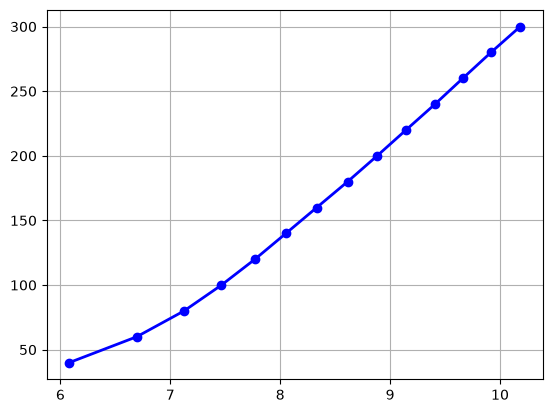

In [8]:
alt = [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]
means = []

# 各高度の平均値を計算してリストに溜める
for h in alt:
    mean_val = df_all[f"{h}m Wind Speed (m/s)"].mean()
    means.append(mean_val)

# 横軸：平均風速、縦軸：高度 でプロット
#plt.figure(figsize=(6, 8))
plt.plot(means, alt, marker="o", color="blue", linewidth=2)
#plt.xlabel("Mean Wind Speed (m/s)")
#plt.ylabel("Altitude (m)")
plt.grid(True)
plt.show()

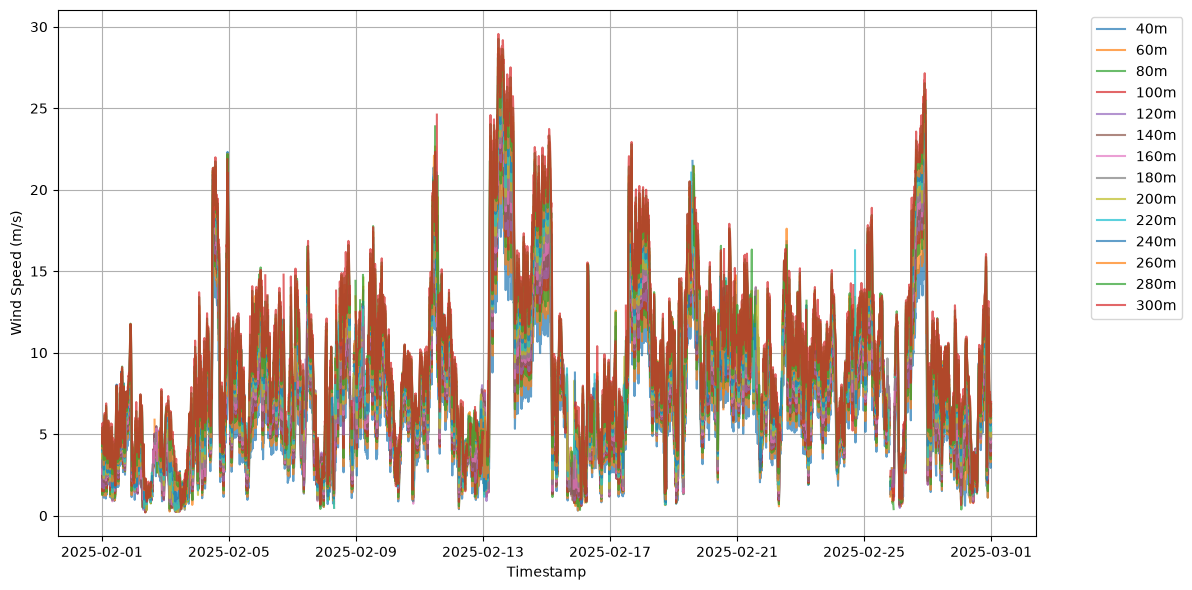

In [9]:
alt = [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]

plt.figure(figsize=(12, 6))

for h in alt:
    # .mean() を外すことで、X軸と同じ4002行のデータになり、サイズが一致します
    plt.plot(
        df_all["Timestamp (end of interval)"],
        df_all[f"{h}m Wind Speed (m/s)"],
        label=f"{h}m",
        alpha=0.7,  # 線が重なって見にくくなるのを防ぐため少し透過
    )

plt.xlabel("Timestamp")
plt.ylabel("Wind Speed (m/s)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")  # 凡例を外側に配置
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
df_spped = pd.read_pickle("wind_speed_data.pkl")

In [11]:
import matplotlib.pyplot as plt

In [12]:
mean_speed = df_speed[f'40m Wind Speed (m/s)'].mean()
print(mean_speed)   

6.080688084998735


14


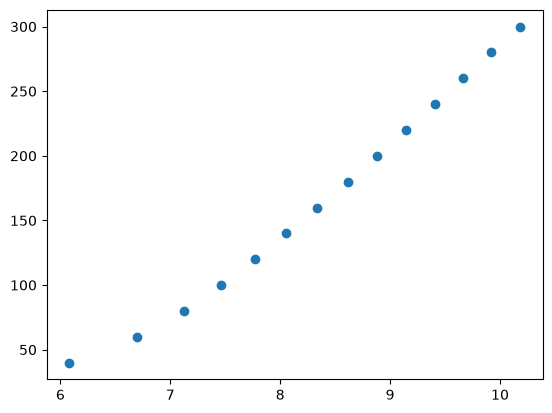

In [13]:
alt=[40,60,80,100,120,140,160,180,200,220,240,260,280,300]
mean_speed_list=[]
for i in range (len(alt)):
    mean_speed = df_speed[f'{i*20+40}m Wind Speed (m/s)'].mean()
    mean_speed_list.append(mean_speed)
print(len(mean_speed_list))
plt.scatter(mean_speed_list,alt)

In [14]:
www=df_speed.iloc[0,1:].mean()
www

np.float64(3.748571428571428)

In [23]:

ts = pd.to_datetime(df_all["Timestamp (end of interval)"])

df_LLJ = df_all[
    (ts >= "2025-02-12 21:00:00") &
    (ts <= "2025-02-13 03:00:00")
].copy()

In [24]:
df_LLJ

,Timestamp (end of interval),Int Temp (ｰC),Ext Temp (ｰC),Pressure (hPa),Rel Humidity (%),Wiper count,Vbatt (V),40m Wind Speed (m/s),40m Wind Speed Dispersion (m/s),40m Wind Speed min (m/s),40m Wind Speed max (m/s),40m Wind Direction (ｰ),40m Z-wind (m/s),40m Z-wind Dispersion (m/s),40m CNR (dB),...,280m CNR (dB),280m CNR min (dB),280m Dopp Spect Broad (m/s),280m Data Availability (%),300m Wind Speed (m/s),300m Wind Speed Dispersion (m/s),300m Wind Speed min (m/s),300m Wind Speed max (m/s),300m Wind Direction (ｰ),300m Z-wind (m/s),300m Z-wind Dispersion (m/s),300m CNR (dB),300m CNR min (dB),300m Dopp Spect Broad (m/s),300m Data Availability (%)
1695,2025-02-12 21:00:00,4.5,555.35,5555.35,555.35,0,NaN,1.87,0.28,1.05,2.88,198.12,-0.02,0.17,-17.86,...,-21.38,-22.99,0.15,80.13,3.88,0.68,2.17,5.44,167.14,-0.14,0.57,-22.08,-22.97,0.35,22.37
1696,2025-02-12 21:10:00,4.5,555.35,5555.35,555.35,0,NaN,2.43,0.43,1.47,3.37,173.15,0.02,0.17,-16.55,...,-21.36,-22.98,0.14,88.81,3.45,0.75,1.47,5.10,173.00,0.02,0.64,-22.08,-22.99,0.27,34.72
1697,2025-02-12 21:20:00,3.7,555.35,5555.35,555.35,0,NaN,2.82,0.30,2.09,3.52,170.29,0.03,0.14,-16.31,...,-21.46,-23.00,0.17,49.42,2.82,0.60,1.36,4.19,191.63,-0.12,0.64,-21.96,-22.95,0.37,11.52
1698,2025-02-12 21:30:00,3.6,555.35,5555.35,555.35,0,NaN,3.08,0.27,2.36,3.84,147.74,-0.15,0.15,-15.77,...,-22.07,-22.99,0.29,11.35,3.36,NaN,3.78,3.78,219.81,0.42,0.17,-22.79,-22.79,0.70,0.17
1699,2025-02-12 21:40:00,3.5,555.35,5555.35,555.35,0,NaN,3.14,0.32,2.40,4.16,146.98,-0.15,0.16,-15.74,...,-22.33,-22.90,0.53,2.17,NaN,NaN,NaN,NaN,NaN,0.28,0.17,-23.89,-32.45,1.64,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1727,2025-02-13 02:20:00,3.2,555.35,5555.35,555.35,0,NaN,1.72,0.82,0.45,3.66,134.33,-0.12,0.21,-16.09,...,-24.55,-31.41,0.62,0.00,NaN,NaN,NaN,NaN,NaN,-1.09,0.70,-25.59,-35.94,2.82,0.00
1728,2025-02-13 02:30:00,3.3,555.35,5555.35,555.35,0,NaN,2.70,0.72,1.05,4.13,128.97,-0.01,0.22,-16.42,...,-25.40,-34.96,0.02,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-26.69,-41.86,NaN,0.00
1729,2025-02-13 02:40:00,3.1,555.35,5555.35,555.35,0,NaN,2.60,0.39,1.62,3.68,142.56,-0.11,0.20,-16.99,...,-25.38,-37.61,1.32,0.00,NaN,NaN,NaN,NaN,NaN,0.40,NaN,-26.15,-42.95,2.17,0.00
1730,2025-02-13 02:50:00,3.0,555.35,5555.35,555.35,1,NaN,2.74,0.73,0.38,3.97,129.33,-0.15,0.30,-16.20,...,-26.00,-35.36,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-27.20,-39.61,NaN,0.00


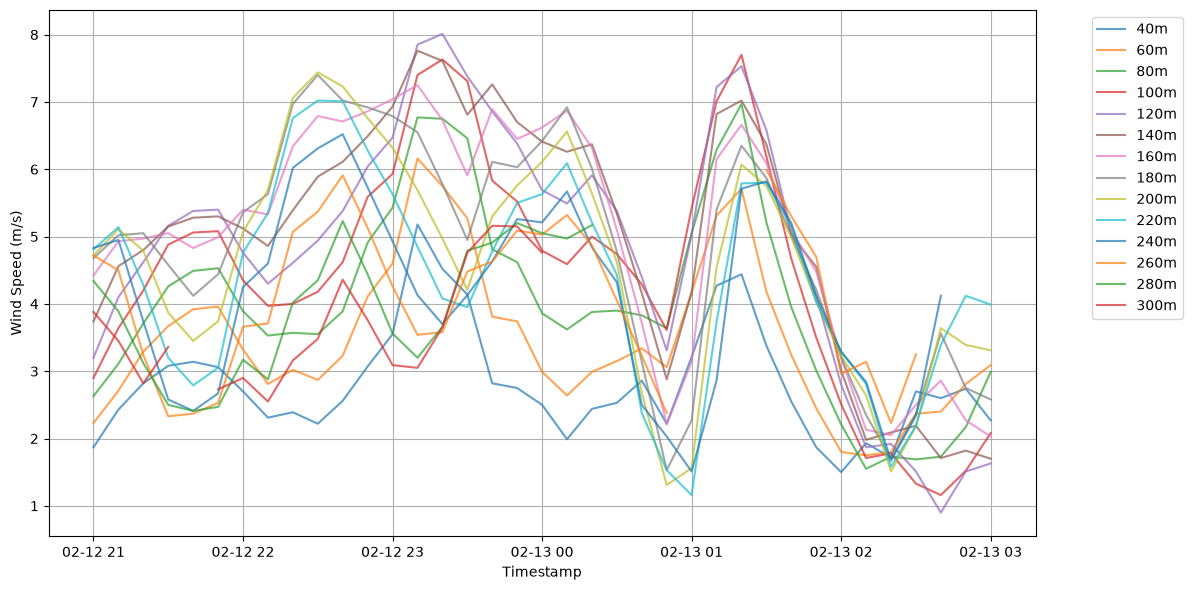

In [25]:
alt = [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]

plt.figure(figsize=(12, 6))

for h in alt:
    # .mean() を外すことで、X軸と同じ4002行のデータになり、サイズが一致します
    plt.plot(
        df_LLJ["Timestamp (end of interval)"],
        df_LLJ[f"{h}m Wind Speed (m/s)"],
        label=f"{h}m",
        alpha=0.7,  # 線が重なって見にくくなるのを防ぐため少し透過
    )

plt.xlabel("Timestamp")
plt.ylabel("Wind Speed (m/s)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")  # 凡例を外側に配置
plt.grid(True)
plt.tight_layout()
plt.show()